Original dataset:
   job_id              company_name    industry                 job_title  \
0       1           Foster and Sons  Healthcare              Data Analyst   
1       2   Boyd, Myers and Ramirez        Tech  Computer Vision Engineer   
2       3                  King Inc        Tech          Quant Researcher   
3       4  Cooper, Archer and Lynch        Tech        AI Product Manager   
4       5                  Hall LLC     Finance            Data Scientist   

                                     skills_required experience_level  \
0  NumPy, Reinforcement Learning, PyTorch, Scikit...              Mid   
1                    Scikit-learn, CUDA, SQL, Pandas           Senior   
2          MLflow, FastAPI, Azure, PyTorch, SQL, GCP            Entry   
3       Scikit-learn, C++, Pandas, LangChain, AWS, R              Mid   
4                    Excel, Keras, SQL, Hugging Face           Senior   

  employment_type               location salary_range_usd posted_date  \
0      

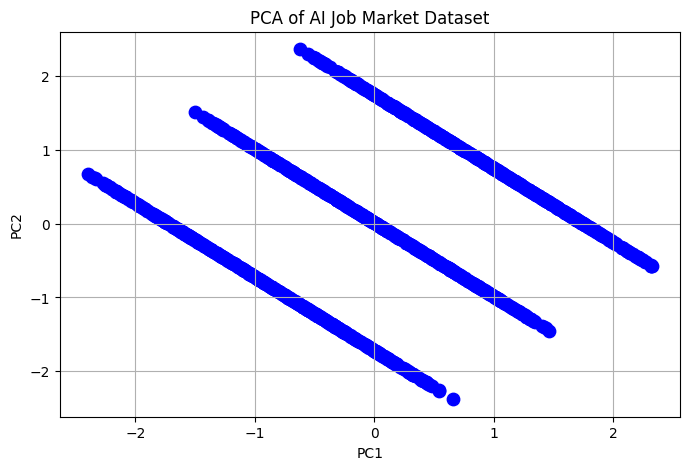

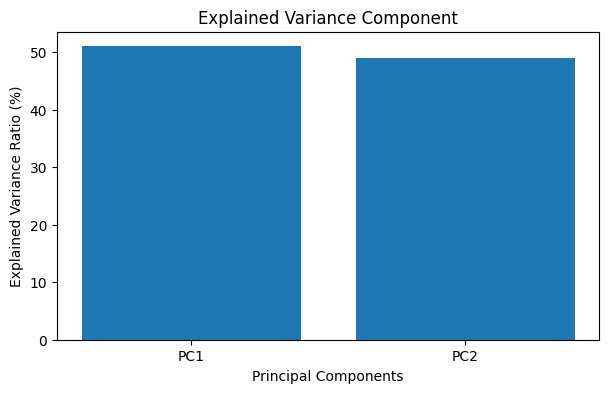

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

# Load dataset
df = pd.read_csv(r"/content/ai_job_market.csv")
print("Original dataset:")
print(df.head())

# Parse salary_range_usd (e.g., '92860-109598') to a single numeric average salary
def parse_salary(val):
    try:
        if pd.isna(val):
            return np.nan
        parts = str(val).split('-')
        return np.mean([float(parts[0]), float(parts[1])])
    except:
        return np.nan

df['salary_average'] = df['salary_range_usd'].apply(parse_salary)

# Select only the numerical columns for scaling and PCA
# (We exclude identifier columns like job_id if we only want features, but we can include it or other numeric features here)
numeric_cols = ['salary_average']
# Let's drop rows with missing values in our features
df_numeric = df[numeric_cols].dropna()

print("\nNumerical dataset for processing:")
print(df_numeric.head())

# Apply Normalisation
normalizer = MinMaxScaler()
normalized_data = normalizer.fit_transform(df_numeric)
normalized_df = pd.DataFrame(normalized_data, columns=df_numeric.columns)
print("\nNormalized Dataset (First 5 rows):")
print(normalized_df.head().round(2))

# Apply Standardization
scaler = StandardScaler()
standardized_data = scaler.fit_transform(df_numeric)
standardized_df = pd.DataFrame(standardized_data, columns=df_numeric.columns)
print("\nStandardized Dataset (First 5 rows):")
print(standardized_df.head().round(2))
print("\nMean of standardized features:", standardized_df.mean().round(2).values)
print("Standard deviation of standardized features:", standardized_df.std(ddof=0).round(2).values)

# For 2-component PCA, we need at least 2 features.
# Since there is only one parsed continuous feature here, let's create a dummy or encode another column
# (e.g. converting 'company_size' to numeric category)
company_size_map = {'Startup': 1, 'Medium': 2, 'Large': 3}
df['company_size_num'] = df['company_size'].map(company_size_map).fillna(2)

# Let's use both features for PCA
pca_features = ['salary_average', 'company_size_num']
X = df[pca_features].dropna()

# Step 1: Standardize the features before PCA
X_scaled = scaler.fit_transform(X)

# Step 2: Create PCA with two components
pca = PCA(n_components=2)

# Step 3: Transform the standardized data
pca_data = pca.fit_transform(X_scaled)

# Step 4: Store the results in DataFrame
pca_df = pd.DataFrame(data=pca_data, columns=['PC1', 'PC2'])
print("\nPCA Transformed Results (First 5 rows):")
print(pca_df.head().round(2))

# Display explained variance
print("\nExplained variance Ratio:", pca.explained_variance_ratio_.round(4))
print("Total Variance Retained:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

# Visualize the PCA results
plt.figure(figsize=(8, 5))
plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    color='blue',
    s=80
)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA of AI Job Market Dataset')
plt.grid(True)
plt.show()

# Plot explained variance
plt.figure(figsize=(7, 4))
components = ['PC1', 'PC2']
plt.bar(components, pca.explained_variance_ratio_ * 100)
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance Ratio (%)')
plt.title('Explained Variance Component')
plt.show()